# Thí nghiệm E4: Countdown × Qwen2.5-1.5B-Instruct

Countdown (dùng các số cho trước và + − × ÷ để ra số đích) với mô hình 1,5B, cùng dữ liệu và cách chia của run Countdown 0,5B trong báo cáo, để so sánh hai cỡ mô hình.

Notebook chạy theo đúng luồng của người nghiên cứu trên lab HeteroES:

| Bước | Ở đây |
|---|---|
| Mô hình | `Model.from_hf` ghim một commit Hugging Face; **mỗi máy tự tải từ Hugging Face** và kiểm SHA-256 từng tệp |
| Dữ liệu | `Dataset.from_rows` (train / validation / test cố định, ghim mã băm) |
| Chạy | `ESTrainer.submit(lab, coordinator, workers)`: lab xếp hàng, chia candidate cho các GPU, chấm chéo (audit) |
| Nối tiếp | mỗi đoạn sau bắt đầu từ trọng số cuối đã kiểm chứng của đoạn trước (`derive_model`) |
| Đánh giá | chọn checkpoint bằng validation; tập test chỉ chấm **một lần** ở cuối, kiểm định McNemar |

Các đoạn và lý do chọn tham số nằm ở `decisions/e4-countdown-qwen15.json`; mã thí nghiệm trên lab ở `state/e4-countdown-qwen15.json`. Chạy lại
notebook sẽ gắn vào các run đã có (không chạy lại). Đặt `CHAY_MOI = True` để chạy một run ngắn mới khi demo.

## 1. Chuẩn bị: kết nối lab và xem các GPU

In [1]:
import json
import sys
import time
from pathlib import Path

HERE = Path.cwd()
SRC = (HERE / ".." / ".." / "src").resolve()  # runtime/notebooks/experiments -> runtime/src
for path in (str(SRC), str(HERE)):
    if path not in sys.path:
        sys.path.insert(0, path)

import runner  # noqa: E402  (sets a clean Hugging Face cache first)
import tasks  # noqa: E402
from heteroes.sdk import ESConfig, ESTrainer, reward  # noqa: E402
from heteroes.sdk_lab import Dataset, Lab, Model  # noqa: E402

NAME = 'e4-countdown-qwen15'
CHAY_MOI = False  # True: a short new run for a live demo (a few generations) instead of re-attaching to the recorded one
COORDINATOR = '5070ti-nhan'  # the coordinator goes to a GPU (owner rule)
EXCLUDE = {'1660s'}  # names of devices to leave out of a new segment

experiment = runner.Experiment(NAME + (time.strftime("-demo-%Y%m%d-%H%M") if CHAY_MOI else ""))
lab = Lab.from_session()  # python3 scripts/lab-login.py signs in once (12 hours)


def online_workers():
    return [d.name for d in lab.devices() if d.online and d.on and not d.cpu_only and d.name not in EXCLUDE]


for d in lab.devices():
    print(f"{d.name:16} {d.gpu:28} {d.vram_gb:5.1f} GB  online={d.online} ON={d.on} bận={d.busy}")

5070ti-nhan      NVIDIA GeForce RTX 5070 Ti    15.9 GB  online=True ON=True bận=False
3060-quang       NVIDIA GeForce RTX 3060       12.0 GB  online=False ON=True bận=False
1660s            NVIDIA GeForce GTX 1660 SUPER   6.0 GB  online=False ON=False bận=False
5070ti-nhut      NVIDIA GeForce RTX 5070 Ti    15.9 GB  online=True ON=True bận=False
3060-thao        NVIDIA GeForce RTX 3060       12.0 GB  online=True ON=False bận=False


## 2. Dữ liệu

In [2]:
from heteroes.v3 import data as v3data

splits = v3data.build(tasks.countdown(), split_seed=42)["splits"]  # the split of the 0.5B Countdown run
splits = {k: [dict(r) for r in v] for k, v in splits.items()}
data = Dataset.from_rows(**splits, directory=experiment.dir / "data")
print({k: len(v) for k, v in splits.items()}, "| mã băm dữ liệu", data.sha256[:16], "…")
print(splits["test"][0]["prompt"], "→ số đích", splits["test"][0]["target"])

{'train': 2000, 'validation': 250, 'test': 250} | mã băm dữ liệu 2141b135ab507673 …
Using the numbers [16, 23, 13], create an equation that equals 69. You can use basic arithmetic operations (+, -, *, /) and each number can only be used once. Show your work in <think> </think> tags. And return the final answer in <answer> </answer> tags, for example <answer> (1 + 2) / 3 </answer>. → số đích 69


## 3. Mô hình

`Qwen/Qwen2.5-1.5B-Instruct` được ghim theo commit `989aa7980e4c…`. Trên lab đây là mô hình **tham chiếu**: lab không giữ bản
sao, mỗi worker tự tải từ Hugging Face rồi kiểm tra mã băm từng tệp trước khi làm việc.

In [3]:
model = Model.from_hf('Qwen/Qwen2.5-1.5B-Instruct', revision='989aa7980e4cf806f80c7fef2b1adb7bc71aa306')
print(model.id, model.revision[:12], model.source)
for file, sha in model.manifest["files"].items():
    print(f"  {file:28} {sha[:16]}…")

/home/pc5070ti/miniforge3/envs/heteroes-match/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 1900.21it/s]

Qwen/Qwen2.5-1.5B-Instruct 989aa7980e4c REFERENCE
  config.json                  98d2ff8cc47488d0…
  generation_config.json       e558847a8b440261…
  merges.txt                   599bab5407508877…
  model.safetensors            dd924a11b4c220f3…
  tokenizer.json               c0382117ea329cdf…
  tokenizer_config.json        5b5d4f65d0acd3b2…
  vocab.json                   ca10d7e9fb3ed185…


## 4. Reward

Reward của một candidate là trung bình điểm trên lô 32 câu train. Trên tập test, **"đúng" nghĩa là điểm 1** (đáp án
chính xác).

In [4]:
SCORER = {"name": "countdown", "config": {"numbersField": "nums", "targetField": "target"}}
TEST_SCORER = SCORER  # "đúng" = score 1: a valid expression over the given numbers that equals the target
make_reward = dict(scorer=SCORER)

### Mô hình gốc trả lời thế nào?

Ba câu test đầu, giải mã tham lam bằng bộ suy luận nghiêm ngặt `strict_b22_v1` như trong thí nghiệm (tối đa 384
token).

In [5]:
sample = splits["test"][:3]
before = runner.score_model(model.path, sample, TEST_SCORER, 384)
for row, text, s in zip(sample, before["outputs"], before["scores"]):
    print(f"[điểm {s}]", repr(text[-300:]))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:  72%|███████▏  | 244/338 [00:00<00:00, 2421.44it/s]

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 2609.66it/s]

[điểm 0.1] "addition, subtraction, multiplication, or division.\n</think>\n\nLet's try:\n\\( 16 \\times 23 - 13 = 69 \\)\n\nHere's how we got this:\n- First, multiply 16 and 23: \\( 16 \\times 23 = 368 \\)\n- Then subtract 13 from 368: \\( 368 - 13 = 69 \\)\n\nSo, the equation is:\n\n<answer> \\( 16 \\times 23 - 13 = 69 \\) </answer>"
[điểm 0.1] "eate an equation using the numbers [8, 2, 31] that equals 70.\nLet's try different combinations:\n(31 * 2) - 8 = 62 - 8 = 54\nThis doesn't equal 70 yet.\n\nAnother combination:\n(31 * 2) + 8 = 62 + 8 = 70\n\nSo, our equation is: \n\\( (31 \\times 2) + 8 = 70 \\)\n</think>\n\n<answer>(31 \\times 2) + 8 = 70</answer>"
[điểm 0.1] "<think>\nWe need to find an equation using the numbers [16, 42, 57] with the operation of addition, subtraction, multiplication, or division.\n</think>\n\nLet's try:\n\\( 42 - 16 = 26 \\)\nNow we have \\( 26 + 57 = 83 \\)\n\nSo the equation is: \n<answer> \\( 42 - 16 + 57 \\)</answer>"


## 5. Cấu hình

32 candidate mỗi thế hệ, mỗi candidate chấm trên 32 câu train; σ và α theo từng đoạn. Validation
(tập validation) được chấm mỗi 25 thế hệ trên coordinator.

In [6]:
def make_trainer(model, segment):
    args = ESConfig(
        model=model,
        dataset=data,
        population=32,
        batch_size=32,
        generations=3 if CHAY_MOI else segment["generations"],
        alpha=segment["alpha"],
        sigma=segment["sigma"],
        max_new_tokens=384,
        eval_dtype="float16",
        decoder="strict_b22_v1",  # same tokens on every supported NVIDIA GPU
        eval_chunk=32,
        validation_interval=25,
        audit_rate=0.05,
    )
    return ESTrainer(args, code_dir=experiment.dir / "code", **make_reward)


segments = experiment.segments({'alpha': 0.0005, 'sigma': 0.001, 'generations': 150, 'reason': 'tham số của Qiu et al. 2025 (ES cho LLM): σ = 0,001, α = 5·10⁻⁴, khoảng 30 candidate'})
for i, s in enumerate(segments, 1):
    print(f"đoạn {i}: α={s['alpha']} σ={s['sigma']} {s['generations']} thế hệ — {s['reason']}")

đoạn 1: α=0.0005 σ=0.001 150 thế hệ — tham số của Qiu et al. 2025 (ES cho LLM): σ = 0,001, α = 5·10⁻⁴, khoảng 30 candidate


## 6. Chạy trên lab

Mỗi đoạn là một experiment trên lab. Ô này chờ đến khi các đoạn xong (xem trực tiếp trên trang Experiments của lab);
khi chạy lại notebook, các đoạn đã có chỉ được gắn lại.

In [7]:
runs = runner.run_segments(lab, experiment, model, make_trainer, segments, COORDINATOR, online_workers)
for (segment, run, _), i in zip(runs, range(1, len(runs) + 1)):
    print(f"đoạn {i}: {run.id} {run.status()} {run.url}")

segment-01: đã có run 12aaaa92640d45ab80cae3e99cbc36dd


segment-01: dừng sớm (CANCELLED) — lab hủy run ở thế hệ 123/150 lúc 10:33 ngày 25/11 do lỗi lab (gỡ một worker rồi tắt máy đó làm hủy cả run; đã sửa ở commit 85e3d630). Dùng điểm khôi phục đã kiểm chứng mới nhất: thế hệ 110.
đoạn 1: 12aaaa92640d45ab80cae3e99cbc36dd CANCELLED https://lab.heteroes.site/experiments/12aaaa92640d45ab80cae3e99cbc36dd


## 7. Quá trình học

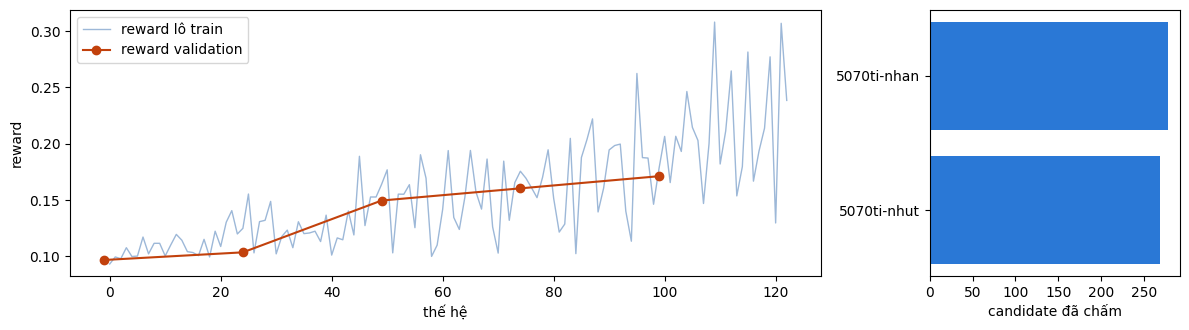

validation: [(-1, 0.0968), (24, 0.1036), (49, 0.1496), (74, 0.1604), (99, 0.1712)]


In [8]:
import matplotlib.pyplot as plt

rewards, validation, work = runner.history(runs)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [3, 1]})
a.plot([g for g, _ in rewards], [r for _, r in rewards], color="#9db8d8", lw=1, label="reward lô train")
a.plot([g for g, _ in validation], [r for _, r in validation], "o-", color="#c2410c", label="reward validation")
for end in [sum(s["generations"] for s, _, _ in runs[:k]) for k in range(1, len(runs))]:
    a.axvline(end - 0.5, color="#999", ls=":", lw=1)
a.set_xlabel("thế hệ")
a.set_ylabel("reward")
a.legend()
names = {d.worker_id: d.name for d in lab.devices()}
b.barh([names.get(w, w) for w in work], list(work.values()), color="#2a78d6")
b.set_xlabel("candidate đã chấm")
plt.tight_layout()
plt.show()
print("validation:", [(g, round(r, 4)) for g, r in validation])

## 8. Chọn checkpoint và chấm test (một lần)

Checkpoint được chọn là cuối đoạn có reward validation cao nhất. Tập test được chấm cho mô hình gốc, cuối đoạn đầu và
checkpoint được chọn; kết quả lưu lại nên chạy lại notebook không chấm lại.

In [9]:
ends = []
for k, (segment, run, _) in enumerate(runs, 1):
    marks = [v for v in run.results()["validation"] if v["generation"] is not None]
    ends.append((marks[-1]["reward"], k))
best = max(ends)[1]
print("validation cuối mỗi đoạn:", ends, "→ chọn đoạn", best)

done = [(s, r, m) for s, r, m in runs]
first_dir = runner.after_segment(lab, experiment, done, 1).path
best_dir = runner.after_segment(lab, experiment, done, best).path
rows = splits["test"]
base = runner.test_report(experiment, "base", -1, model.path, rows, TEST_SCORER, 384)
first = runner.test_report(experiment, "first", 1, first_dir, rows, TEST_SCORER, 384)
chosen = runner.test_report(experiment, f"segment-{best:02d}", best, best_dir, rows, TEST_SCORER, 384)
for label, report in (("mô hình gốc", base), ("cuối đoạn 1", first), (f"chọn (đoạn {best})", chosen)):
    ok, n = runner.correct(report)
    print(f"{label:16} đúng {ok}/{n} = {ok / n:6.1%}   reward {report['checkpoints'][0]['meanReward']:.4f}")

validation cuối mỗi đoạn: [(0.17120000000000002, 1)] → chọn đoạn 1


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:  79%|███████▉  | 268/338 [00:00<00:00, 2651.24it/s]

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 2782.71it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 16984.45it/s]

... (4 outputs left out)

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 22304.51it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 16984.24it/s]

mô hình gốc      đúng 4/250 =   1.6%   reward 0.0896
cuối đoạn 1      đúng 31/250 =  12.4%   reward 0.2112
chọn (đoạn 1)    đúng 31/250 =  12.4%   reward 0.2112


In [10]:
from heteroes.v3.comparison import compare

result = compare(base, chosen)
print(f"gốc → chọn: sửa đúng {result['fixed']}, làm sai {result['broke']}, McNemar p = {result['mcnemarExactP']:.2g}, "
      f"khoảng tin cậy 95% của mức tăng reward [{result['bootstrapCI'][0]:.3f}; {result['bootstrapCI'][1]:.3f}]")
if best != 1:
    later = compare(first, chosen)
    print(f"đoạn 1 → chọn: sửa {later['fixed']}, làm sai {later['broke']}, p = {later['mcnemarExactP']:.2g}")

gốc → chọn: sửa đúng 28, làm sai 1, McNemar p = 1.1e-07, khoảng tin cậy 95% của mức tăng reward [0.086; 0.160]


## 9. Ví dụ trước / sau

In [11]:
shown = 0
for i, row in enumerate(rows):
    a, b = base["checkpoints"][0], chosen["checkpoints"][0]
    if a["scores"][i] != 1 and b["scores"][i] == 1:
        print("—", row["prompt"][:200].replace("\n", " "))
        print("  gốc :", repr(a["outputs"][i][-200:]))
        print("  sau :", repr(b["outputs"][i][-200:]))
        shown += 1
    if shown == 3:
        break

— Using the numbers [96, 31, 17], create an equation that equals 82. You can use basic arithmetic operations (+, -, *, /) and each number can only be used once. Show your work in <think> </think> tags. 
  gốc : "<think>\nWe need to find an equation using the numbers [96, 31, 17] that equals 82.\nLet's try different combinations:\n(96 - 31) * 17 = 82\n</think>\n\n<answer>(96 - 31) * 17 = 82</answer>"
  sau : '<think>\n96 - 31 = 65  \n65 + 17 = 82\n</think>\n\n<answer>(96 - 31) + 17</answer>'
— Using the numbers [41, 63, 66], create an equation that equals 44. You can use basic arithmetic operations (+, -, *, /) and each number can only be used once. Show your work in <think> </think> tags. 
  gốc : '{66}{\\frac{22}{6}} = 44 \\)\n- Further simplify: \\( \\frac{66 \\times 6}{22} = 44 \\)\n- Finally: \\( 3 \\times 6 = 44 \\)\n\nSo, one possible solution is:\n\\[ \\boxed{\\left(\\frac{66}{\\frac{63 - 41}{6}}\\right)} \\]'
  sau : '<think>\n41 - 63 + 66 = 44\n</think>\n\n<answer>(41 - 63) + 

## 10. Lưu tóm tắt (cho notebook tổng hợp)

In [12]:
summary = {
    "name": NAME, "model": model.id, "revision": model.revision, "segments": [{**s, "experimentId": r.id} for s, r, _ in runs],
    "validation": validation, "workPerDevice": {names.get(w, w): c for w, c in work.items()},
    "test": {label: dict(zip(("correct", "count"), runner.correct(rep))) | {"meanReward": rep["checkpoints"][0]["meanReward"]}
             for label, rep in (("base", base), ("first", first), ("selected", chosen))},
    "selectedSegment": best, "comparison": result,
}
out = runner.HERE / "results" / f"{experiment.name}.json"
out.parent.mkdir(exist_ok=True)
out.write_text(json.dumps(summary, indent=1, ensure_ascii=False) + "\n")
print("đã lưu", out)

đã lưu /home/pc5070ti/projects/heteroes/runtime/notebooks/experiments/results/e4-countdown-qwen15.json
